In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
print(len(words))
print(max(len(w) for w in words))
print(words[:8])

32033
15
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [3]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [4]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t):
  ex = torch.all(dt == t.grad).item()
  app = torch.allclose(dt, t.grad)
  maxdiff = (dt - t.grad).abs().max().item()
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

In [6]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 64 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
# Layer 1

# kaiming 初始化公式：std = gain / sqrt(fan_in)
fan_in = n_embd * block_size
W1 = torch.randn((fan_in, n_hidden), generator=g) * (5/3)/((fan_in)**0.5)  # 详细解释看04.ipynb
b1 = torch.randn(n_hidden,                        generator=g) * 0.1 # 无用，被BN消除

# Layer 2
# *0.1 是为了让初始logits小一些，softmax比较均匀，防止梯度消失
# 1. logits = [8, 1, -2] → softmax ≈ [0.999, 0.001, 0]，饱和，梯度僵住
# 2. logits = [0.8, 0.1, -0.2] → softmax ≈ [0.55, 0.27, 0.18]，梯度很好，模型有调整空间
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1
b2 = torch.randn(vocab_size,                      generator=g) * 0.1

# BatchNorm parameters
# 用非零、非均匀的随机初始化，每个参数的梯度都被"激活"，准确验证手算的结果
bngain = torch.randn((1, n_hidden))*0.1 + 1.0
bnbias = torch.randn((1, n_hidden))*0.1

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

4137


In [7]:
batch_size = 32
n = batch_size # a shorter variable also, for convenience
# construct a minibatch
ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # 一个batch, 随机 32 个下标
Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
Xb.shape

torch.Size([32, 3])

In [12]:
# forward pass, "chunkated" into smaller steps that are possible to backward one at a time

emb = C[Xb] # embed the characters into vectors  # (32, 3, 10)
embcat = emb.view(emb.shape[0], -1) # concatenate the vectors # (32, 30)
# Linear layer 1
hprebn = embcat @ W1 + b1 # hidden layer pre-activation # (32, 30) @ (30, 64) + (64,) = (32, 64)
# BatchNorm layer
bnmeani = 1/n*hprebn.sum(0, keepdim=True) # 等价 hpreact.mean(0, keepdim=True)
bndiff = hprebn - bnmeani # 偏差，每个值与mean的距离
bndiff2 = bndiff**2 # 偏差的平方，求导用
bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True) # note: Bessel's correction (dividing by n-1, not n)  方差
bnvar_inv = (bnvar + 1e-5)**-0.5 # 1/√(Var+eps), std的倒数  
bnraw = bndiff * bnvar_inv # 即 (hprebn - bnmeani) / bnstdi
hpreact = bngain * bnraw + bnbias
# Non-linearity
h = torch.tanh(hpreact) # hidden layer
# Linear layer 2
logits = h @ W2 + b2 # output layer, softmax前的分数
# cross entropy loss (same as F.cross_entropy(logits, Yb))
logit_maxes = logits.max(1, keepdim=True).values  # 每个样本(每行)的最大logit # (32, 1)
norm_logits = logits - logit_maxes # subtract max for numerical stability，整体平移数值稳定   # (32, 27)
counts = norm_logits.exp()  # (32, 27)  = e^{z - max}
counts_sum = counts.sum(1, keepdims=True)  # (32, 1)  = Σ_j e^{z_j - max}
counts_sum_inv = counts_sum**-1 # if I use (1.0 / counts_sum) instead then I can't get backprop to be bit exact...   # (32, 1)  = 1/sum
probs = counts * counts_sum_inv # # (32, 27) = softmax 概率
logprobs = probs.log() #  取对数
loss = -logprobs[range(n), Yb].mean() # 挑出每个样本"正确字符"那一列的对数概率，对 batch 平均，取负

# PyTorch backward pass
for p in parameters:
  p.grad = None #  PyTorch 的 .backward() 是累加梯度的（p.grad += new_grad），不是覆盖。不清空就会把多个 batch 的梯度加在一起。
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv, # afaik there is no cleaner way
          norm_logits, logit_maxes, logits, h, hpreact, bnraw,
         bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmeani,
         embcat, emb]:
  t.retain_grad() # 强制保存所有grad,  默认行为：PyTorch 只保留"叶子张量"（C、W1、bngain…）的 .grad，中间张量的梯度用完就丢弃（为了省内存）
loss.backward()
loss

tensor(3.3488, grad_fn=<NegBackward0>)

In [9]:
# Exercise 1: backprop through the whole thing manually, 
# backpropagating through exactly all of the variables 
# as they are defined in the forward pass above, one by one

# -----------------
# YOUR CODE HERE :)
# -----------------

# dlogprobs = ∂loss / ∂logprobs 
# loss = -(1/n) * Σ_b logprobs[b, Yb[b]] = -(1/n) · [ logprobs[0,Yb₀] + logprobs[1,Yb₁] + ... + logprobs[n-1,Yb_{n-1}] ]
# 对某个元素 logprobs[b,j] 求偏导
# 若 j == Yb[b], 导数 dlogprobs[b, j] = -1/n， 否则为0
dlogprobs = torch.zeros_like(logprobs) 
dlogprobs[range(n), Yb] = -1.0/n # 标记”正确答案“位置的梯度为-1/n

# dprobs = ∂loss / ∂logprobs * ∂logprobs / ∂probs
# logprobs = probs.log()
# (lnx)' = 1/x
dprobs = (1.0 / probs) * dlogprobs

# dcounts_sum_inv = dprobs *  ∂dcounts_sum_inv / ∂probs
# probs = counts * counts_sum_inv
# counts_sum_inv (32, 1)
# dprobs (32, 27)
# counts (32, 27)
# probs (32, 27)
# 要将shape还原成(32, 1)
dcounts_sum_inv = (counts * dprobs).sum(1, keepdim=True)

# dcounts
# 下游一：
# probs = counts * counts_sum_inv
# dcounts = ∂loss / ∂probs * ∂probs / ∂counts
# counts (32, 27)
# counts_sum_inv (32, 1)
# dprobs (32, 27)
# 下游二：
# counts_sum = counts.sum(1, keepdims=True)
# dcounts = ∂loss / ∂counts_sum * ∂counts_sum / ∂counts
# counts_sum[b] = counts[b,0] + counts[b,1] + counts[b,2] + ... + counts[b,26]
# 任一项求偏导：∂counts_sum[b] / ∂counts[b,0] = 1
# 即 torch.one_like(counts)
dcounts = counts_sum_inv * dprobs

# dcounts_sum
# counts_sum_inv = counts_sum**-1 = 1/counts_sum 
dcounts_sum = (-counts_sum**-2) * dcounts_sum_inv # (32,1)   ← x^-1 的导数

# dcounts path 2
dcounts += torch.ones_like(counts) * dcounts_sum

# dnorm_logits
# counts = norm_logits.exp()  # (32, 27)  (e^x)' = e^x
# dnorm_logits = ∂loss / ∂counts * ∂counts / ∂dnorm_logits
dnorm_logits = norm_logits.exp() * dcounts

# dlogit_maxes 
# norm_logits = logits - logit_maxes
# dlogit_maxes = ∂loss / ∂norm_logits * ∂norm_logits / ∂logit_maxes
# logit_maxes (32, 1)
# norm_logits (32, 27)
dlogit_maxes = (-dnorm_logits).sum(1, keepdim=True)

# dlogits
# norm_logits = logits - logit_maxes
# dlogit = ∂loss / ∂norm_logits * ∂norm_logits / ∂logits
dlogits = dnorm_logits.clone()
# logit_maxes = logits.max(1, keepdim=True).values
# dlogit = ∂loss / ∂logit_maxes * ∂logit_maxes / ∂logits
# logit_maxes[b] = max( logits[b,0], logits[b,1], ..., logits[b,26] )
#    max([1, 5, 3]) = 5，argmax = 1
#    ∂max/∂logits = [0, 1, 0]        ← 只有 argmax 位置是 1
# 即选中的最大值的导数是1，其他为0 （max是开关，对logits的导数做一次筛选，没用的归零）
indices = logits.max(1).indices 
dlogits +=  F.one_hot(indices, num_classes=27) * dlogit_maxes

# dh
# logits = h @ W2 + b2
# dh = ∂loss / ∂logits * ∂logits / ∂h
# h  (32, 64)
# W2 (64, 27)
# logits (32, 27)
dh = dlogits @ W2.T

# dW2
# logits = h @ W2 + b2
# dW2 = ∂loss / ∂logits * ∂logits / ∂W2
dW2 = h.T @ dlogits

# db2
# db2 = ∂loss / ∂logits * ∂logits / ∂b2
# b2 (27,)
# logits (32, 27)
db2 = dlogits.sum(0)

# dhpreact
# h = torch.tanh(hpreact)
# dhpreact = ∂loss / ∂h * ∂h / ∂hpreact
# tanh'(x) = 1 - tanh(x)^2
dhpreact = (1 - h**2) * dh


# hpreact = bngain * bnraw + bnbias
# hpreact (32, 64)   bngain (1, 64)  bnraw (32, 64)  bnbias (1, 64) 
#    hpreact[b,j] = bngain[0,j] * bnraw[b,j] + bnbias[0,j]
#                   b = 0..31      b = 0..31      b = 0..31
#                   j = 0..63      j = 0..63      j = 0..63
# 链式法则：总导数 = 所有路径贡献之和
# 对每个输入，问「它的一个元素在正向被用了几次？」
# bngain[0,j] 被用在:  hpreact[0,j], hpreact[1,j], hpreact[2,j], ..., hpreact[31,j]
# 贡献了32条路径
# dbngain[j] =  Σ_b  dhpreact[b,j] * bnraw[b,j]
# 同理：
#  每个bnraw[b][j]只贡献一个h[b,j]，所以不用求和
#  每个bnbias[0,j]贡献32个hpreact，所以要求和

# dbngain
# hpreact = bngain * bnraw + bnbias
# dbngain = ∂loss / ∂hpreact * ∂hpreact / ∂bngain
# hpreact (32, 64)
# bngain (1, 64)
dbngain = (bnraw * dhpreact).sum(0, keepdim=True)

# bnbias
# hpreact = bngain * bnraw + bnbias
# dbngain = ∂loss / ∂hpreact * ∂hpreact / ∂bnbias
# bnbias (1, 64)
dbnbias = dhpreact.sum(0, keepdim=True)

# bnraw
# hpreact = bngain * bnraw + bnbias
# dbnraw = ∂loss / ∂hpreact * ∂hpreact / ∂bnraw
# hpreact (32, 64)
# bnraw (32, 64)
dbnraw = bngain * dhpreact

# bnvar_inv
# bnraw = bndiff * bnvar_inv
# dbnvar_inv = ∂loss / ∂bnraw * ∂bnraw / ∂bnvar_inv
# bnraw[b,j] = bndiff[b,j] * bnvar_inv[0,j]
# 每个bnvar_inv[0,j]贡献32个bnraw，要求和
# bndiff (32, 64)
# bnraw (32, 64)
# bnvar_inv (1, 64) bnvar是按列求和，每个神经元在32个样本上的方差
dbnvar_inv = (bndiff * dbnraw).sum(0,keepdim=True)

# bnvar
# bnvar_inv = (bnvar + 1e-5)**-0.5
# dbnvar = ∂loss / ∂bnvar_inv * ∂bnvar_inv / ∂bnvar
dbnvar = (-0.5 * (bnvar + 1e-5)**(-1.5)) * dbnvar_inv

# bndiff2 (32, 64)
# bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True)
# dbnvar = ∂loss / ∂bnvar * ∂bnvar / ∂bndiff2
# bnvar[0,j] = (1/(n-1)) * (bndiff2[0,j] + bndiff2[1,j] ... bndiff2[31,j])
# 每个bndiff2[0,j] 只贡献一个 bnvar[0,j]
# ∂bnvar[0,j] / ∂bndiff2[b,j] = 1/(n-1)
# dbndiff2[b,j] = dbnvar[0,j] * 1/(n-1)
dbndiff2 = (1.0/(n-1)) * torch.ones_like(bndiff2) * dbnvar # 先构造 (32,64)，再*(1,64)

# bndiff (32, 64)
# bnraw = bndiff * bnvar_inv
# dbndiff = ∂loss / ∂bnraw * ∂bnraw / ∂bndiff
dbndiff = bnvar_inv * dbnraw
# path2:
# bndiff2 = bndiff**2
dbndiff += (2*bndiff) * dbndiff2

# bnmeani (1, 64)
# bndiff = hprebn - bnmeani
# dbnmeani = ∂loss / ∂bndiff * ∂bndiff / ∂bnmeani
# 每个bnmean[0,j]贡献64个bndiff[b,j], 每个梯度都是-1
dbnmeani = (-1 * dbndiff).sum(0, keepdim=True)

# hprebn (32, 64)
# bnmeani = 1/n*hprebn.sum(0, keepdim=True)
#  bnmeani[0,j] = (1/n) * ( hprebn[0,j] + hprebn[1,j] + ... + hprebn[31,j] )
#  ∂bnmeani[0,j] / ∂hprebn[b,j] = 1/n
# path2:
# bndiff = hprebn - bnmeani 
dhprebn = dbndiff.clone()
dhprebn += (1.0/n) * torch.ones_like(hprebn) * dbnmeani     # (1,64) 复制成 (32,64)

# W1 (30, 64)
# hprebn = embcat @ W1 + b1
# hprebn (32, 64)
# embcat (32, 30)
# dW1 = ∂loss / ∂hprebn * ∂hprebn / ∂W1
dW1 = embcat.T @ dhprebn

# embcat (32,30)
dembcat = dhprebn @ W1.T

# b1 (64,)
db1 = dhprebn.sum(0)

# emb (32, 3, 10)
# embcat = emb.view(emb.shape[0], -1)
demb = dembcat.view(emb.shape)

# C (27, 10)
# emb (32, 3, 10)
# emb = C[Xb]
# Xb (32,3) <- 32个样本，每个3个字符
# emb[b,t,:] = C[Xb[b,t], :]        # C 的一行被"取出来"放到 emb 的某个位置
dC = torch.zeros_like(C)
for b in range(32):
    for t in range(3):
        dC[Xb[b,t]] += demb[b,t] # C中被选中的字符加上demb

cmp('logprobs', dlogprobs, logprobs)
cmp('probs', dprobs, probs)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)
cmp('counts_sum', dcounts_sum, counts_sum)
cmp('counts', dcounts, counts)
cmp('norm_logits', dnorm_logits, norm_logits)
cmp('logit_maxes', dlogit_maxes, logit_maxes)
cmp('logits', dlogits, logits)
cmp('h', dh, h)
cmp('W2', dW2, W2)
cmp('b2', db2, b2)
cmp('hpreact', dhpreact, hpreact)
cmp('bngain', dbngain, bngain)
cmp('bnbias', dbnbias, bnbias)
cmp('bnraw', dbnraw, bnraw)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)
cmp('bnvar', dbnvar, bnvar)
cmp('bndiff2', dbndiff2, bndiff2)
cmp('bndiff', dbndiff, bndiff)
cmp('bnmeani', dbnmeani, bnmeani)
cmp('hprebn', dhprebn, hprebn)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)
cmp('emb', demb, emb)
cmp('C', dC, C)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logit_maxes     | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
hpreact         | exact: True  | approximate: True  | maxdiff: 0.0
bngain          | exact: True  | approximate: True  | maxdiff: 0.0
bnbias          | exact: True  | approximate: True  | maxdiff: 0.0
bnraw           | exact: True  | approximate: True  | maxdiff:

In [14]:
# Exercise 2: backprop through cross_entropy but all in one go
# to complete this challenge look at the mathematical expression of the loss,
# take the derivative, simplify the expression, and just write it out

# forward pass

# before:
# logit_maxes = logits.max(1, keepdim=True).values
# norm_logits = logits - logit_maxes # subtract max for numerical stability
# counts = norm_logits.exp()
# counts_sum = counts.sum(1, keepdims=True)
# counts_sum_inv = counts_sum**-1 # if I use (1.0 / counts_sum) instead then I can't get backprop to be bit exact...
# probs = counts * counts_sum_inv
# logprobs = probs.log()
# loss = -logprobs[range(n), Yb].mean()

# now:
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff:', (loss_fast - loss).item())

3.3487629890441895 diff: 0.0


In [15]:
Yb.shape

torch.Size([32])

In [16]:
dlogits.shape

torch.Size([32, 27])

In [18]:
# Yb[n] 是第 n 个样本的真实类别索引 i  (32,)
dlogits = F.softmax(logits, 1) # softmax自带exp(), 算出全部 pn,k (第n个样本，模型预测它属于第 k 类的概率)
dlogits[range(n), Yb] -= 1     # 对每个样本的logit，在它真实标签那一列位置减去 1，就得到了梯度 （对应上面的推导）
dlogits /= n                   # 因为loss用的是n个样本的平均损失，所以梯度也要平均

cmp('logits', dlogits, logits) # I can only get approximate to be true, my maxdiff is 6e-9

logits          | exact: False | approximate: True  | maxdiff: 5.3551048040390015e-09


In [19]:
logits.shape, Yb.shape

(torch.Size([32, 27]), torch.Size([32]))

In [20]:
F.softmax(logits, 1)[0]

tensor([0.0694, 0.0839, 0.0166, 0.0501, 0.0188, 0.0751, 0.0261, 0.0359, 0.0191,
        0.0318, 0.0408, 0.0380, 0.0391, 0.0283, 0.0335, 0.0148, 0.0088, 0.0207,
        0.0148, 0.0575, 0.0522, 0.0203, 0.0273, 0.0709, 0.0583, 0.0244, 0.0234],
       grad_fn=<SelectBackward0>)

In [21]:
dlogits[0] * n

tensor([ 0.0694,  0.0839,  0.0166,  0.0501,  0.0188,  0.0751,  0.0261,  0.0359,
        -0.9809,  0.0318,  0.0408,  0.0380,  0.0391,  0.0283,  0.0335,  0.0148,
         0.0088,  0.0207,  0.0148,  0.0575,  0.0522,  0.0203,  0.0273,  0.0709,
         0.0583,  0.0244,  0.0234], grad_fn=<MulBackward0>)

In [22]:
dlogits[0].sum() # 0

tensor(-1.8626e-09, grad_fn=<SumBackward0>)

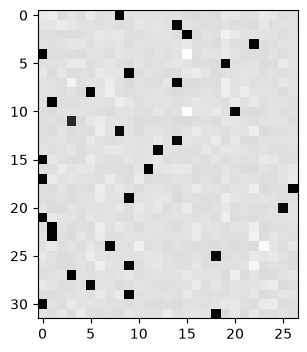

In [24]:
# 每一行，正确的位置为黑色【向下】，其他位置【向上】，这些【向上】【向下】之和为0
plt.figure(figsize=(4, 4))
plt.imshow(dlogits.detach(), cmap='gray')

In [25]:
# Exercise 3: backprop through batchnorm but all in one go
# to complete this challenge look at the mathematical expression of the output of batchnorm,
# take the derivative w.r.t. its input, simplify the expression, and just write it out

# forward pass

# before:
# bnmeani = 1/n*hprebn.sum(0, keepdim=True)
# bndiff = hprebn - bnmeani
# bndiff2 = bndiff**2
# bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True) # note: Bessel's correction (dividing by n-1, not n)
# bnvar_inv = (bnvar + 1e-5)**-0.5
# bnraw = bndiff * bnvar_inv
# hpreact = bngain * bnraw + bnbias

# now:
hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdim=True)) / torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5) + bnbias
print('max diff:', (hpreact_fast - hpreact).abs().max())

max diff: tensor(4.7684e-07, grad_fn=<MaxBackward1>)


In [ ]:
# backward pass

# before we had:
# dbnraw = bngain * dhpreact
# dbndiff = bnvar_inv * dbnraw
# dbnvar_inv = (bndiff * dbnraw).sum(0, keepdim=True)
# dbnvar = (-0.5*(bnvar + 1e-5)**-1.5) * dbnvar_inv
# dbndiff2 = (1.0/(n-1))*torch.ones_like(bndiff2) * dbnvar
# dbndiff += (2*bndiff) * dbndiff2
# dhprebn = dbndiff.clone()
# dbnmeani = (-dbndiff).sum(0)
# dhprebn += 1.0/n * (torch.ones_like(hprebn) * dbnmeani)

# calculate dhprebn given dhpreact (i.e. backprop through the batchnorm)
# (you'll also need to use some of the variables from the forward pass up above)

# -----------------
# YOUR CODE HERE :)
dhprebn = None # TODO. my solution is 1 (long) line
# -----------------

cmp('hprebn', dhprebn, hprebn) # I can only get approximate to be true, my maxdiff is 9e-10